# TED 03: modelagem e avaliação

A etapa está descrita nas seções 8 a 10 de `docs/JuriPredict_Documento_Tecnico_BigData.pdf`. Depende de `data/processed/processos.jsonl`, gerado pelo notebook da TED 02.

Este notebook executa `src/ted03_modelar.py`: separa o teste, calcula as linhas de base, roda os experimentos E1 a E6 por validação cruzada, avalia o modelo escolhido no teste, mede abstenção e generalização e grava `resultados/ted03_resultados.json`, `resultados/ted03_particao.csv`, as figuras e o modelo em `data/processed/modelo_status.joblib` (não versionado). Usa três processos em paralelo.

In [1]:
import json, os, subprocess, sys, time
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ = Path.cwd().parents[1]
RESULTADOS = RAIZ / "resultados"
pd.set_option("display.float_format", lambda x: f"{x:.0f}" if float(x).is_integer() else f"{x:.4f}")


def rodar(*args):
    """Executa um comando Python a partir da raiz do repositório e informa quanto tempo levou."""
    inicio = time.time()
    r = subprocess.run([sys.executable, *args], cwd=RAIZ, capture_output=True, text=True, encoding="utf-8",
                       env={**os.environ, "PYTHONIOENCODING": "utf-8", "PYTHONDONTWRITEBYTECODE": "1"})
    if r.returncode:
        raise RuntimeError(r.stderr[-3000:])
    print(f"{' '.join(args)}: {(time.time() - inicio) / 60:.1f} min")
    return r.stdout


def figuras(*nomes):
    for nome in nomes:
        display(Image(filename=RESULTADOS / "figuras" / f"{nome}.png"))

In [2]:
rodar("src/ted03_modelar.py");

src/ted03_modelar.py: 10.1 min


## Experimentos na validação cruzada

In [3]:
res = json.loads((RESULTADOS / "ted03_resultados.json").read_text(encoding="utf-8"))
linhas = {"base: " + k: v for k, v in res["linhas_de_base_dev"].items()}
linhas |= {f"E1: janela {k}": v for k, v in res["e1_janela"].items()}
linhas |= {f"E3: {k}": v for k, v in res["e3_algoritmos"].items()}
linhas |= {f"E4: {k}": v for k, v in res["e4_atributos"].items()}
linhas["E5: vocabulário da base sem rótulo"] = res["e5_sem_rotulo"]
linhas["E6: busca de hiperparâmetros"] = res["e6_busca"]
pd.DataFrame(linhas).T[["f1_macro", "f1_macro_dp", "acuracia"]]

,f1_macro,f1_macro_dp,acuracia
base: maioria,0.2139,0.0001,0.4723
base: regra,0.7750,NaN,0.8132
E1: janela 1,0.7448,0.0125,0.8214
E1: janela 2,0.8723,0.0151,0.9090
E1: janela 3,0.8869,0.0132,0.9238
E1: janela 5,0.8937,0.0099,0.9283
E1: janela 10,0.8807,0.0068,0.9222
E1: janela 20,0.8522,0.0132,0.9006
E1: janela 50,0.7981,0.0186,0.8670
E1: janela todas,0.7610,0.0238,0.8462


In [4]:
print("melhores hiperparâmetros (E6):", res["e6_busca"]["melhores"])

melhores hiperparâmetros (E6): {'ultima__ngram_range': '(1, 2)', 'C': '30', 'class_weight': 'balanced'}


## Conjunto de teste

In [5]:
t = res["teste"]
print("F1 macro do modelo, intervalo de 95%:", t["modelo"]["f1_macro_ic95"])
print("ganho de F1 sobre a regra, intervalo de 95%:", t["modelo"]["ganho_f1_sobre_regra_ic95"])
pd.DataFrame({m: {k: t[m][k] for k in ["f1_macro", "acuracia", "acuracia_balanceada"]}
              for m in ["maioria", "regra", "modelo"]}).T

F1 macro do modelo, intervalo de 95%: [0.8568, 0.9093]
ganho de F1 sobre a regra, intervalo de 95%: [0.1063, 0.1664]


,f1_macro,acuracia,acuracia_balanceada
maioria,0.2138,0.4721,0.3333
regra,0.7499,0.7926,0.7251
modelo,0.8848,0.9222,0.8735


In [6]:
pd.DataFrame(t["modelo"]["por_classe"]).T

,precision,recall,f1-score,support
arquivado,0.9611,0.9052,0.9323,601
ativo,0.8984,0.9704,0.9330,574
suspenso,0.8391,0.7449,0.7892,98


In [7]:
pd.DataFrame(t["matriz_confusao"], index=["real: arquivado", "real: ativo", "real: suspenso"],
             columns=["prev.: arquivado", "prev.: ativo", "prev.: suspenso"])

,prev.: arquivado,prev.: ativo,prev.: suspenso
real: arquivado,544,46,11
real: ativo,14,557,3
real: suspenso,8,17,73


## Abstenção e generalização

In [8]:
pd.DataFrame(res["abstencao"]).set_index("limiar")

,cobertura,n,acuracia,f1_macro
limiar,,,,
0,1,1273,0.9222,0.8848
0.5000,0.9953,1267,0.9258,0.8898
0.6000,0.9709,1236,0.9337,0.8980
0.7000,0.9505,1210,0.9397,0.9088
0.8000,0.9222,1174,0.9497,0.9219
0.9000,0.8633,1099,0.9682,0.9490
0.9500,0.7722,983,0.9715,0.9547


In [9]:
pd.DataFrame({k: {c: v[c] for c in ["n_treino", "n_teste", "acuracia", "f1_macro"]}
              for k, v in res["generalizacao"].items()}).T

,n_treino,n_teste,acuracia,f1_macro
treino SP -> teste RJ,5852,511,0.9061,0.9100
treino RJ -> teste SP,511,5852,0.5203,0.3002
treino ate 2017 -> teste 2018-2019,2881,2874,0.7679,0.7535
treino ate 2018 -> teste 2019,4383,1366,0.9217,0.7316


## Gráficos

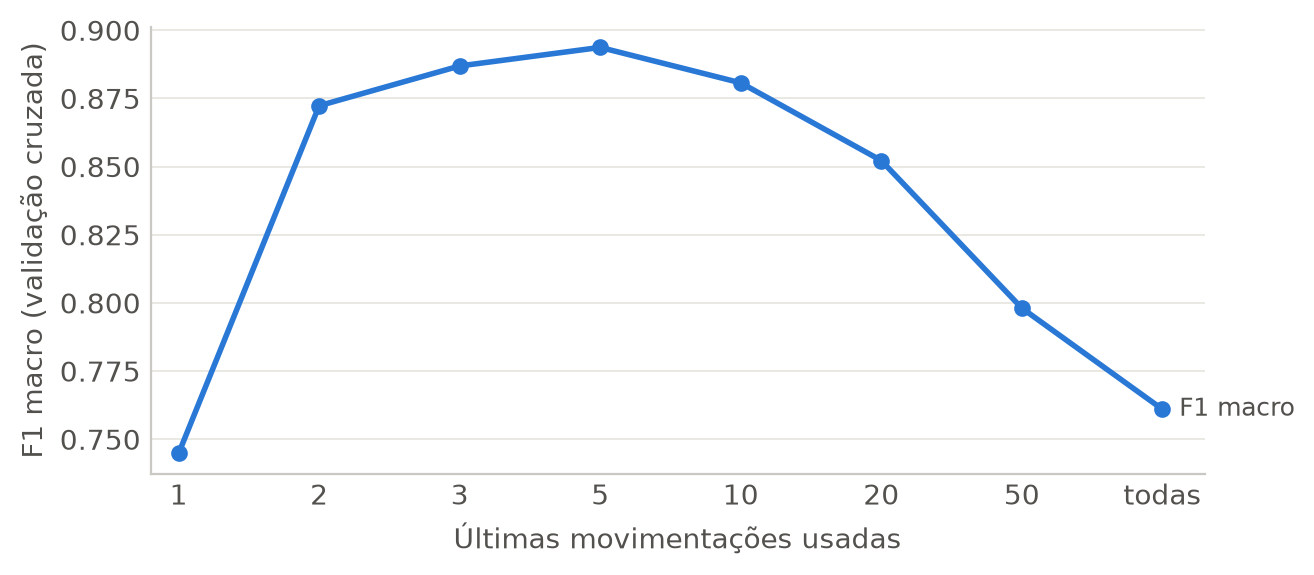

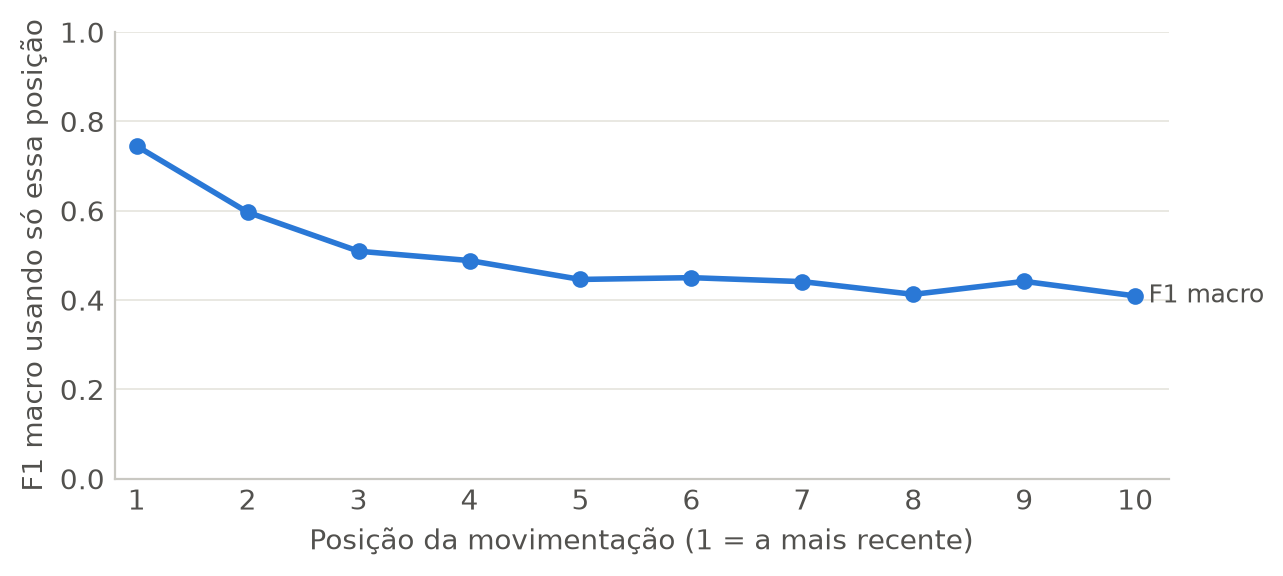

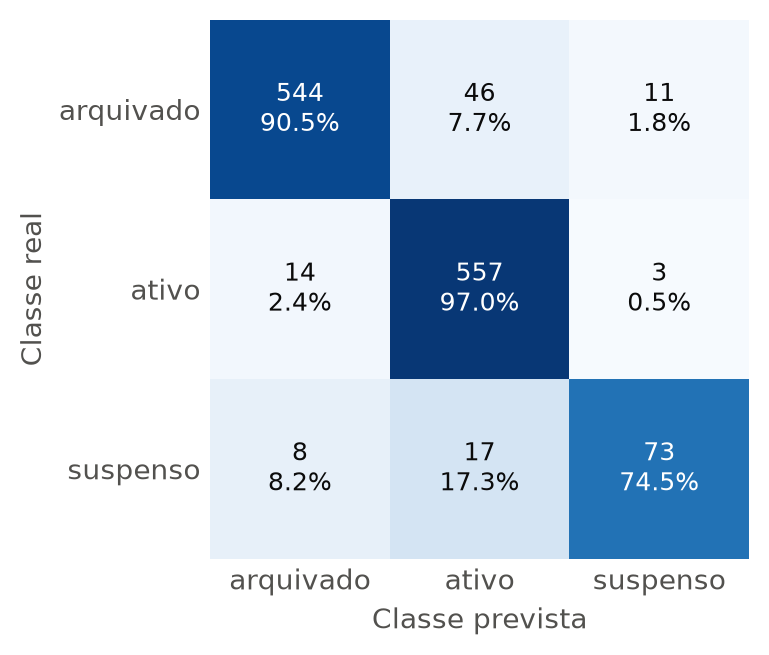

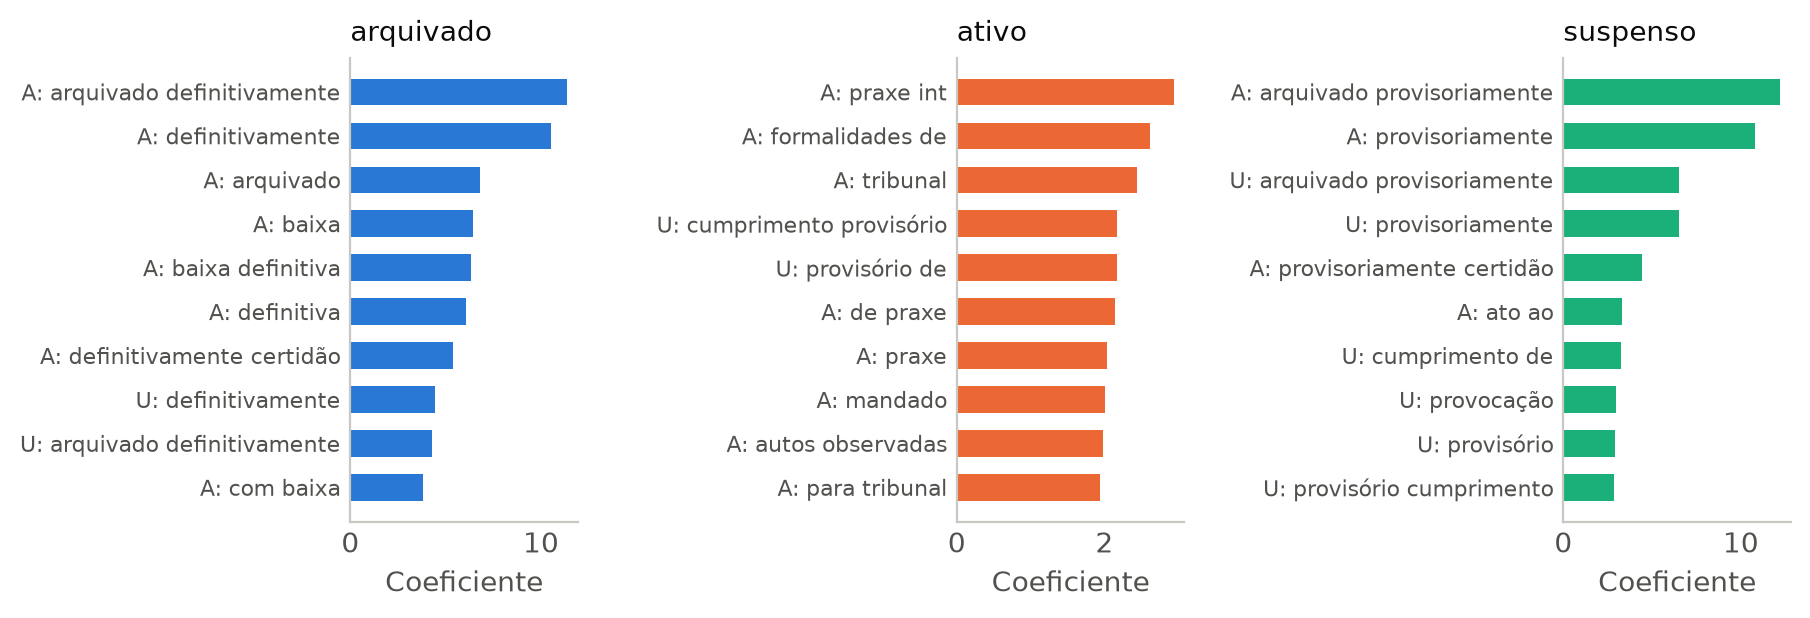

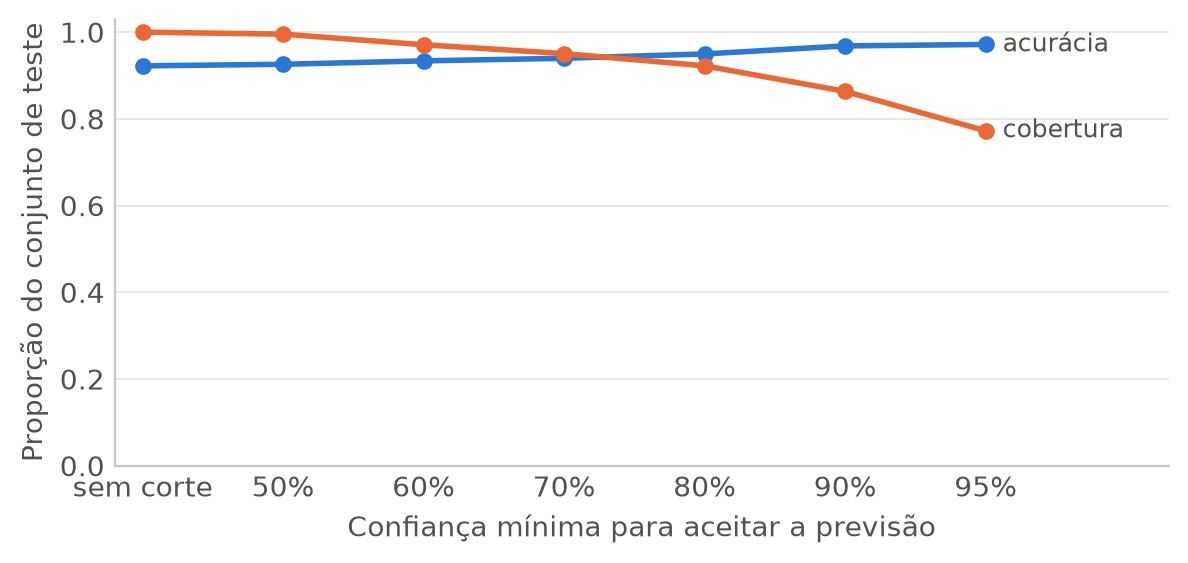

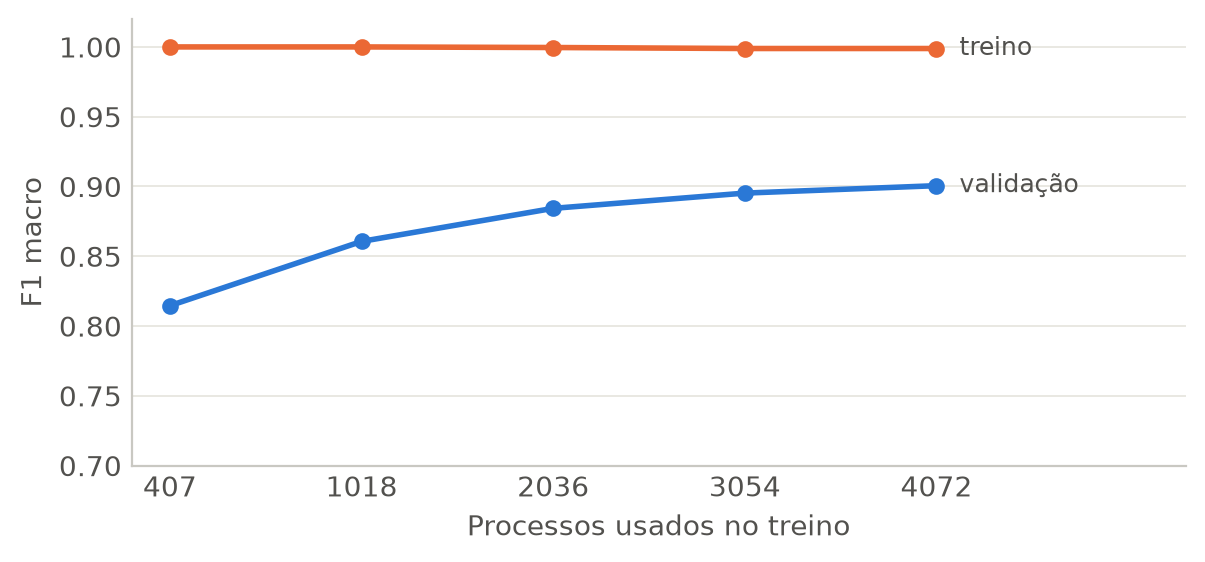

In [10]:
figuras("fig_janela", "fig_posicao", "fig_confusao", "fig_coeficientes", "fig_abstencao", "fig_aprendizado")